# 3. Bounded search

Can repeated search find useful connections when the initial pools miss necessary inputs?

The target has 108 independent inputs, four LTUs with four inputs each, and four outputs with two LTUs each.
The output noise has standard deviation 0.1. The task stays fixed.

Both proposed methods limit every unit to 32 slots plus a bias. They use 64 hidden units and four outputs.
New inputs come from uniform draws. Parent weights provide no clues about input choices.
New hidden units retain random initial weights and a random shadow sign on an actual output connection.
Parent choices use gated progress from `output_prioritization/3_progress.ipynb`.

The fixed-pool baseline permits activation within its initial pools, but no source or unit replacement.
The all-input baseline uses 16 hidden units, the original sign rule, and guidance from parent weights.
Both baselines and both proposed methods use 2,244 total slots, biases included.
The ideal reference knows the target connections but learns the weights. It uses 32 slots, biases included.

The fixed-pool baseline should fail, while the all-input baseline should approach the ideal reference.
Then the proposed methods should match the equal-budget baseline and eventually approach the ideal reference.

Each method uses five seeds with the same targets and examples. The curves show mean RMSE without uncertainty bands.

Fixed pools fail on this problem. Separate candidates approach the ideal reference but remain above the all-input baseline.
Small initial steps learn more slowly.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
results = m.run_fixed()


fixed: final RMSE 0.604


all_inputs: final RMSE 0.144


ideal: final RMSE 0.163


candidates: final RMSE 0.155


single: final RMSE 0.190


75.1s for 5 seeds per method


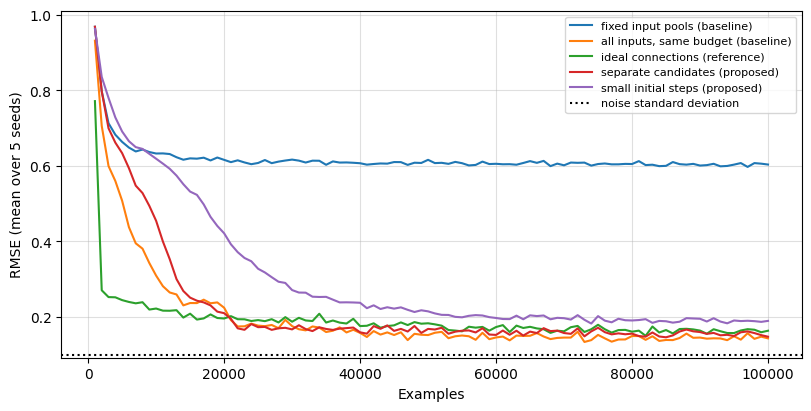

In [3]:
m.plot(results)
